In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree
from pathlib import Path
import math
import time
import torch
import torch.nn as nn

In [19]:
class ResidualBlock(nn.Module):

    def __init__(self, dim):
        super().__init__()

        self.block = nn.Sequential(
            nn.Linear(dim, dim),
            nn.LeakyReLU(0.02),

            nn.Linear(dim, dim)
        )

        self.act = nn.LeakyReLU(0.02)

    def forward(self, x):

        return self.act(
            x + self.block(x)
        )

In [20]:
def gather_centroids(points, centroid_indices):
    """
    points:
        [B, N, C]

    centroid_indices:
        [B, N']

    returns:
        [B, N', C]
    """

    batch_size = points.shape[0]

    batch_indices = torch.arange(
        batch_size,
        device=points.device
    ).view(batch_size, 1)

    sampled_points = points[
        batch_indices,
        centroid_indices
    ]

    return sampled_points

In [21]:
def gather_neighbors(points, neighbor_indices):
    """
    points:
        [B, N, C]

    neighbor_indices:
        [B, N', K]

    returns:
        [B, N', K, C]
    """

    batch_size = points.shape[0]

    batch_indices = torch.arange(
        batch_size,
        device=points.device
    ).view(batch_size, 1, 1)

    neighbor_points = points[
        batch_indices,
        neighbor_indices
    ]

    return neighbor_points

In [22]:
def farthest_point_sampling(coordinates, number_samples):
    """
    coordinates:
        [B, N, 3]

    returns:
        centroid_indices: [B, number_samples]
    """

    batch_size, number_points, _ = coordinates.shape

    centroid_indices = torch.zeros(
        batch_size,
        number_samples,
        dtype=torch.long,
        device=coordinates.device
    )

    minimum_distances = torch.full(
        (batch_size, number_points),
        float("inf"),
        device=coordinates.device
    )

    farthest_indices = torch.randint(
        low=0,
        high=number_points,
        size=(batch_size,),
        device=coordinates.device
    )

    batch_indices = torch.arange(
        batch_size,
        device=coordinates.device
    )

    for sample_index in range(number_samples):
        centroid_indices[:, sample_index] = farthest_indices

        current_centroid = coordinates[
            batch_indices,
            farthest_indices
        ]

        current_centroid = current_centroid.unsqueeze(1)

        squared_distances = torch.sum(
            (coordinates - current_centroid) ** 2,
            dim=-1
        )

        minimum_distances = torch.minimum(
            minimum_distances,
            squared_distances
        )

        farthest_indices = torch.max(
            minimum_distances,
            dim=1
        ).indices

    return centroid_indices

In [23]:
def compute_knn_between(
    query_coordinates,
    source_coordinates,
    number_neighbors=32,
    chunk_size=2048
):
    """
    query_coordinates:
        [B, N_query, 3]

    source_coordinates:
        [B, N_source, 3]

    returns:
        knn_indices: [B, N_query, K]
    """

    number_query_points = query_coordinates.shape[1]
    number_source_points = source_coordinates.shape[1]

    if number_neighbors > number_source_points:
        raise ValueError(
            f"Requested {number_neighbors} neighbors, "
            f"but only {number_source_points} source points exist."
        )

    index_chunks = []

    for start in range(
        0,
        number_query_points,
        chunk_size
    ):
        end = min(
            start + chunk_size,
            number_query_points
        )

        query_chunk = query_coordinates[
            :,
            start:end,
            :
        ]

        distances = torch.cdist(
            query_chunk,
            source_coordinates
        )

        nearest_indices = torch.topk(
            distances,
            k=number_neighbors,
            dim=-1,
            largest=False,
            sorted=True
        ).indices

        index_chunks.append(
            nearest_indices
        )

    knn_indices = torch.cat(
        index_chunks,
        dim=1
    )

    return knn_indices

In [24]:
def find_three_nearest_neighbors(
    target_coordinates,
    source_coordinates,
    chunk_size=256
):
    """
    target_coordinates:
        [B, Nt, 3]

    source_coordinates:
        [B, Ns, 3]

    returns:
        distances: [B, Nt, 3]
        indices:   [B, Nt, 3]
    """

    number_target_points = target_coordinates.shape[1]

    distance_chunks = []
    index_chunks = []

    for start in range(
        0,
        number_target_points,
        chunk_size
    ):
        end = min(
            start + chunk_size,
            number_target_points
        )

        target_chunk = target_coordinates[
            :,
            start:end,
            :
        ]

        distances = torch.cdist(
            target_chunk,
            source_coordinates
        )

        nearest_distances, nearest_indices = torch.topk(
            distances,
            k=3,
            dim=-1,
            largest=False,
            sorted=True
        )

        distance_chunks.append(
            nearest_distances
        )

        index_chunks.append(
            nearest_indices
        )

    nearest_distances = torch.cat(
        distance_chunks,
        dim=1
    )

    nearest_indices = torch.cat(
        index_chunks,
        dim=1
    )

    return nearest_distances, nearest_indices

In [25]:
def build_hierarchy_level(
    source_coordinates,
    number_neighbors=32,
    knn_chunk_size=2048
):
    """
    source_coordinates:
        [B, N, 3]

    Returns:
        sampled_coordinates:
            [B, ceil(N/2), 3]

        fps_indices:
            [B, ceil(N/2)]

        knn_indices:
            [B, ceil(N/2), K]
    """

    number_source_points = source_coordinates.shape[1]

    number_sampled_points = (
        number_source_points + 3
    ) // 4

    fps_indices = farthest_point_sampling(
        source_coordinates,
        number_sampled_points
    )

    sampled_coordinates = gather_centroids(
        source_coordinates,
        fps_indices
    )

    knn_indices = compute_knn_between(
        query_coordinates=sampled_coordinates,
        source_coordinates=source_coordinates,
        number_neighbors=number_neighbors,
        chunk_size=knn_chunk_size
    )

    return (
        sampled_coordinates,
        fps_indices,
        knn_indices
    )

In [26]:
def build_three_level_hierarchy(
    coordinates,
    number_neighbors=32,
    knn_chunk_size=2048,
    interpolation_chunk_size=128
):
    """
    coordinates:
        [B, N, 3]

    Point hierarchy:
        Level 0: N
        Level 1: ceil(N/2)
        Level 2: ceil(N/4)
        Level 3: ceil(N/8)
    """

    # ========================================================
    # Encoder hierarchy
    # ========================================================

    # Level 0 to Level 1
    coordinates_1, fps_1, knn_1 = build_hierarchy_level(
        source_coordinates=coordinates,
        number_neighbors=number_neighbors,
        knn_chunk_size=knn_chunk_size
    )

    # Level 1 to Level 2
    coordinates_2, fps_2, knn_2 = build_hierarchy_level(
        source_coordinates=coordinates_1,
        number_neighbors=number_neighbors,
        knn_chunk_size=knn_chunk_size
    )

    # Level 2 to Level 3
    coordinates_3, fps_3, knn_3 = build_hierarchy_level(
        source_coordinates=coordinates_2,
        number_neighbors=number_neighbors,
        knn_chunk_size=knn_chunk_size
    )

    # ========================================================
    # Decoder interpolation hierarchy
    # ========================================================

    # Level 3 source to Level 2 target
    interp_dist_3, interp_idx_3 = (
        find_three_nearest_neighbors(
            target_coordinates=coordinates_2,
            source_coordinates=coordinates_3,
            chunk_size=interpolation_chunk_size
        )
    )

    # Level 2 source to Level 1 target
    interp_dist_2, interp_idx_2 = (
        find_three_nearest_neighbors(
            target_coordinates=coordinates_1,
            source_coordinates=coordinates_2,
            chunk_size=interpolation_chunk_size
        )
    )

    # Level 1 source to original Level 0 target
    interp_dist_1, interp_idx_1 = (
        find_three_nearest_neighbors(
            target_coordinates=coordinates,
            source_coordinates=coordinates_1,
            chunk_size=interpolation_chunk_size
        )
    )

    hierarchy = {
        "fps_1": fps_1,
        "knn_1": knn_1,

        "fps_2": fps_2,
        "knn_2": knn_2,

        "fps_3": fps_3,
        "knn_3": knn_3,

        "interp_idx_3": interp_idx_3,
        "interp_dist_3": interp_dist_3,

        "interp_idx_2": interp_idx_2,
        "interp_dist_2": interp_dist_2,

        "interp_idx_1": interp_idx_1,
        "interp_dist_1": interp_dist_1
    }

    return hierarchy


In [35]:
def create_hierarchy_files(
    solids_folder,
    number_neighbors=32,
    knn_chunk_size=2048,
    interpolation_chunk_size=128,
    device="cuda",
    overwrite=False
):
    solids_folder = Path(solids_folder)

    simulation_files = sorted(
        solids_folder.glob("Sim_solids_*.npy")
    )

    if not simulation_files:
        raise FileNotFoundError(
            f"No simulation files found in {solids_folder}"
        )

    processing_device = torch.device(
        "cuda"
        if device == "cuda" and torch.cuda.is_available()
        else "cpu"
    )

    print("Processing device:", processing_device)
    print("Simulation files found:", len(simulation_files))

    for simulation_file in simulation_files:
        simulation_number = (
            simulation_file.stem.split("_")[-1]
        )

        output_file = (
            solids_folder
            / f"hierarchy_solids_{simulation_number}.pt"
        )

        if output_file.exists() and not overwrite:
            existing_hierarchy = torch.load(
                output_file,
                map_location="cpu",
                weights_only=True
            )

            required_keys = [
                "fps_1",
                "knn_1",
                "fps_2",
                "knn_2",
                "fps_3",
                "knn_3",
                "interp_idx_1",
                "interp_dist_1",
                "interp_idx_2",
                "interp_dist_2",
                "interp_idx_3",
                "interp_dist_3"
            ]

            if all(
                key in existing_hierarchy
                for key in required_keys
            ):
                print(
                    f"Skipping {simulation_file.name}: "
                    "complete hierarchy already exists."
                )

                continue

        print("\nProcessing:", simulation_file.name)

        data = np.load(
            simulation_file,
            mmap_mode="r"
        )

        if data.ndim != 2 or data.shape[1] < 3:
            raise ValueError(
                f"Invalid simulation shape in "
                f"{simulation_file.name}: {data.shape}"
            )

        coordinates = torch.from_numpy(
            np.asarray(
                data[:, :3]
            ).copy()
        ).float()

        coordinates = coordinates.unsqueeze(0)

        coordinates = coordinates.to(
            processing_device
        )

        with torch.no_grad():
            hierarchy = build_three_level_hierarchy(
                coordinates=coordinates,
                number_neighbors=number_neighbors,
                knn_chunk_size=knn_chunk_size,
                interpolation_chunk_size=interpolation_chunk_size
            )

        hierarchy_to_save = {}

        for name, tensor in hierarchy.items():
            tensor = tensor.squeeze(0).cpu()

            if "dist" in name:
                hierarchy_to_save[name] = tensor.float()
            else:
                hierarchy_to_save[name] = tensor.long()

        torch.save(
            hierarchy_to_save,
            output_file
        )

        print("Original points:", coordinates.shape[1])

        print(
            "Level 1 points:",
            hierarchy["fps_1"].shape[1]
        )

        print(
            "Level 2 points:",
            hierarchy["fps_2"].shape[1]
        )

        print(
            "Level 3 points:",
            hierarchy["fps_3"].shape[1]
        )

        print("KNN 1:", hierarchy["knn_1"].shape)
        print("KNN 2:", hierarchy["knn_2"].shape)
        print("KNN 3:", hierarchy["knn_3"].shape)

        print(
            "Interpolation 3:",
            hierarchy["interp_idx_3"].shape
        )

        print(
            "Interpolation 2:",
            hierarchy["interp_idx_2"].shape
        )

        print(
            "Interpolation 1:",
            hierarchy["interp_idx_1"].shape
        )

        print("Saved:", output_file.name)

        del data
        del coordinates
        del hierarchy
        del hierarchy_to_save

        if processing_device.type == "cuda":
            torch.cuda.empty_cache()

In [28]:
class LocalPointNet(nn.Module):

    def __init__(
        self,
        input_channels,
        output_channels
    ):
        super().__init__()

        self.mlp = nn.Sequential(
            nn.Linear(input_channels, 64),
            nn.LeakyReLU(negative_slope=0.02),

            nn.Linear(64, 128),
            nn.LeakyReLU(negative_slope=0.02),

            nn.Linear(128, output_channels)
        )

    def forward(self, local_input):
        """
        local_input:
            [B, N', K, 1 + C]

        returns:
            [B, N', output_channels]
        """

        local_features = self.mlp(local_input)

        pooled_features = torch.max(
            local_features,
            dim=2
        ).values

        return pooled_features

In [29]:
class SetAbstraction(nn.Module):

    def __init__(
        self,
        input_feature_channels,
        output_feature_channels
    ):
        super().__init__()

        self.local_pointnet = LocalPointNet(
            input_channels=1 + input_feature_channels,
            output_channels=output_feature_channels
        )

    def forward(
        self,
        coordinates,
        features,
        fps_indices,
        knn_indices
    ):
        """
        coordinates:
            [B, N, 3]

        features:
            [B, N, C]

        fps_indices:
            [B, N']

        knn_indices:
            [B, N', K]

        returns:
            output:
                [B, N', 3 + output_feature_channels]
        """

        fps_indices = fps_indices.long()
        knn_indices = knn_indices.long()

        # Step 1: Gather the precomputed FPS centroids
        centroid_coordinates = gather_centroids(
            coordinates,
            fps_indices
        )

        # Step 2: Gather neighbor coordinates
        neighbor_coordinates = gather_neighbors(
            coordinates,
            knn_indices
        )

        # Step 3: Gather neighbor features
        neighbor_features = gather_neighbors(
            features,
            knn_indices
        )

        # Step 4: Calculate neighbor displacement
        relative_coordinates = (
            neighbor_coordinates
            - centroid_coordinates.unsqueeze(2)
        )

        # Step 5: Calculate scalar distance
        distances = torch.linalg.vector_norm(
            relative_coordinates,
            dim=-1,
            keepdim=True
        )

        # Step 6: Concatenate distance and neighbor features
        local_input = torch.cat(
            [
                distances,
                neighbor_features
            ],
            dim=-1
        )

        # Step 7: Shared MLP and max pooling
        local_features = self.local_pointnet(
            local_input
        )

        # Step 8: Concatenate centroid coordinates and features
        output = torch.cat(
            [
                centroid_coordinates,
                local_features
            ],
            dim=-1
        )

        return output

In [30]:
def gather_features(features, indices):
    """
    features:
    [B, Ns, C]
    
    indices:
    [B, Nt, K]
    
    Returns:
    gathered_features:
    [B, Nt, K, C]

    """
    batch_size = features.shape[0]

    batch_indices = torch.arange(
        batch_size,
        device=features.device
    ).view(batch_size, 1, 1)

    gathered_features = features[
        batch_indices,
        indices
    ]

    return gathered_features

In [31]:
def three_point_interpolation(
    source_features,
    interpolation_indices,
    interpolation_distances,
    power=2
):
    """
    source_features:
        [B, Ns, Cs]

    interpolation_indices:
        [B, Nt, 3]

    interpolation_distances:
        [B, Nt, 3]

    Returns:
        interpolated_features:
            [B, Nt, Cs]
    """

    interpolation_indices = interpolation_indices.long()

    nearest_features = gather_features(
        source_features,
        interpolation_indices
    )

    safe_distances = interpolation_distances.clamp_min(
        1e-10
    )

    weights = torch.reciprocal(
        torch.pow(
            safe_distances,
            power
        )
    )

    weights = weights / weights.sum(
        dim=-1,
        keepdim=True
    )

    interpolated_features = torch.sum(
        nearest_features * weights.unsqueeze(-1),
        dim=2
    )

    return interpolated_features

In [32]:
class SegmentationLayer(nn.Module):

    def __init__(
        self,
        skip_feature_channels,
        source_feature_channels,
        output_feature_channels
    ):
        super().__init__()

        input_channels = (
            skip_feature_channels
            + source_feature_channels
        )

        hidden_channels = max(
            output_feature_channels,
            64
        )

        self.mlp = nn.Sequential(
            nn.Linear(
                input_channels,
                hidden_channels
            ),
            nn.LeakyReLU(
                negative_slope=0.02
            ),

            nn.Linear(
                hidden_channels,
                output_feature_channels
            ),
            nn.LeakyReLU(
                negative_slope=0.02
            )
        )

    def forward(
        self,
        target_coordinates,
        target_skip_features,
        source_features,
        interpolation_indices,
        interpolation_distances
    ):
        """
        target_coordinates:
            [B, Nt, 3]

        target_skip_features:
            [B, Nt, C_skip]

        source_features:
            [B, Ns, C_source]

        interpolation_indices:
            [B, Nt, 3]

        interpolation_distances:
            [B, Nt, 3]

        Returns:
            target_output:
                [B, Nt, 3 + C_out]

            output_features:
                [B, Nt, C_out]
        """

        interpolated_features = three_point_interpolation(
            source_features=source_features,
            interpolation_indices=interpolation_indices,
            interpolation_distances=interpolation_distances,
            power=2
        )

        combined_features = torch.cat(
            [
                target_skip_features,
                interpolated_features
            ],
            dim=-1
        )

        output_features = self.mlp(
            combined_features
        )

        target_output = torch.cat(
            [
                target_coordinates,
                output_features
            ],
            dim=-1
        )

        return target_output, output_features

In [33]:
# ============================================================
# CONFIGURATION
# ============================================================

SOLIDS_FOLDER = Path(r"data/solids")
TRAIN_FOLDER = Path(r"data/solids/train")
VAL_FOLDER = Path(r"data/solids/val")
TEST_FOLDER  = Path(r"data/solids/test")

EPOCHS = 200
NUM_WORKERS = 0    ## This is a parameter that specifies multiple concurrent processes to be used for the data loading process. 

# ============================================================
# CUDA
# ============================================================

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(f"\nUsing device: {device}")

if torch.cuda.is_available():
    print(
        f"GPU: {torch.cuda.get_device_name(0)}"
    )


Using device: cuda
GPU: NVIDIA RTX 5000 Ada Generation Laptop GPU


## Data Loader

### Bottom code run only once

In [37]:
create_hierarchy_files(
    solids_folder=SOLIDS_FOLDER,
    number_neighbors=32,
    knn_chunk_size=2048,
    interpolation_chunk_size=128,
    device="cuda",
    overwrite=False
)

Processing device: cuda
Simulation files found: 13
Skipping Sim_solids_001.npy: complete hierarchy already exists.
Skipping Sim_solids_002.npy: complete hierarchy already exists.
Skipping Sim_solids_003.npy: complete hierarchy already exists.
Skipping Sim_solids_006.npy: complete hierarchy already exists.
Skipping Sim_solids_007.npy: complete hierarchy already exists.
Skipping Sim_solids_008.npy: complete hierarchy already exists.
Skipping Sim_solids_009.npy: complete hierarchy already exists.
Skipping Sim_solids_010.npy: complete hierarchy already exists.
Skipping Sim_solids_011.npy: complete hierarchy already exists.
Skipping Sim_solids_012.npy: complete hierarchy already exists.
Skipping Sim_solids_013.npy: complete hierarchy already exists.
Skipping Sim_solids_014.npy: complete hierarchy already exists.
Skipping Sim_solids_015.npy: complete hierarchy already exists.


In [39]:
import os
import shutil
import random

root = "data/solids"

# Create split folders if they don't exist
for split in ["train", "test", "val"]:
    split_dir = os.path.join(root, split)
    os.makedirs(split_dir, exist_ok=True)

    # Remove existing files
    for f in os.listdir(split_dir):
        file_path = os.path.join(split_dir, f)
        if os.path.isfile(file_path):
            os.remove(file_path)

# Collect simulation files
sim_files = sorted(
    f for f in os.listdir(root)
    if f.startswith("Sim_solids_") and f.endswith(".npy")
)

# Reproducible randomness (optional)
random.seed(42)

# Select one file for validation
val_file = random.choice(sim_files)

remaining = [f for f in sim_files if f != val_file]
random.shuffle(remaining)

# 80:20 split of remaining files
train_count = int(len(remaining) * 0.8)

train_files = remaining[:train_count]
test_files = remaining[train_count:]

def copy_pair(sim_file, split):
    num = sim_file.split("_")[-1].replace(".npy", "")

    hierarchy_file = f"hierarchy_solids_{num}.pt"

    shutil.copy2(
        os.path.join(root, sim_file),
        os.path.join(root, split, sim_file)
    )

    hierarchy_src = os.path.join(root, hierarchy_file)

    if os.path.exists(hierarchy_src):
        shutil.copy2(
            hierarchy_src,
            os.path.join(root, split, hierarchy_file)
        )
    else:
        print(f"Warning: {hierarchy_file} not found")

# Copy validation files
copy_pair(val_file, "val")

# Copy train files
for f in train_files:
    copy_pair(f, "train")

# Copy test files
for f in test_files:
    copy_pair(f, "test")

print("\nValidation:")
print([val_file])

print("\nTrain:")
print(train_files)

print("\nTest:")
print(test_files)


Validation:
['Sim_solids_013.npy']

Train:
['Sim_solids_010.npy', 'Sim_solids_009.npy', 'Sim_solids_003.npy', 'Sim_solids_012.npy', 'Sim_solids_014.npy', 'Sim_solids_008.npy', 'Sim_solids_015.npy', 'Sim_solids_011.npy', 'Sim_solids_006.npy']

Test:
['Sim_solids_007.npy', 'Sim_solids_001.npy', 'Sim_solids_002.npy']


## Run from here again

In [41]:
hierarchy = torch.load(
    TRAIN_FOLDER / "hierarchy_solids_003.pt",
    map_location="cpu",
    weights_only=False
)

for name, tensor in hierarchy.items():
    print(
        name,
        tensor.shape,
        tensor.dtype
    )

fps_1 torch.Size([175509]) torch.int64
knn_1 torch.Size([175509, 32]) torch.int64
fps_2 torch.Size([43878]) torch.int64
knn_2 torch.Size([43878, 32]) torch.int64
fps_3 torch.Size([10970]) torch.int64
knn_3 torch.Size([10970, 32]) torch.int64
interp_idx_3 torch.Size([43878, 3]) torch.int64
interp_dist_3 torch.Size([43878, 3]) torch.float32
interp_idx_2 torch.Size([175509, 3]) torch.int64
interp_dist_2 torch.Size([175509, 3]) torch.float32
interp_idx_1 torch.Size([702035, 3]) torch.int64
interp_dist_1 torch.Size([702035, 3]) torch.float32


In [42]:
def load_simulations(folder):
    folder = Path(folder)

    simulations = []

    simulation_files = sorted(
        folder.glob("Sim_solids_*.npy")
    )

    if len(simulation_files) == 0:
        raise FileNotFoundError(
            f"No simulation files found in {folder}"
        )

    for simulation_file in simulation_files:
        simulation_number = simulation_file.stem.split("_")[-1]

        hierarchy_file = (
            folder
            / f"hierarchy_solids_{simulation_number}.pt"
        )

        if not hierarchy_file.exists():
            raise FileNotFoundError(
                f"Hierarchy file not found for "
                f"{simulation_file.name}: "
                f"{hierarchy_file.name}"
            )

        data = np.load(simulation_file)

        if data.ndim != 2:
            raise ValueError(
                f"{simulation_file.name} must be a 2D array. "
                f"Received shape: {data.shape}"
            )

        if data.shape[1] != 10:
            raise ValueError(
                f"{simulation_file.name} must contain 10 columns. "
                f"Received shape: {data.shape}"
            )

        # Columns 0, 1 and 2 are x, y and z
        coordinates = data[:, 0:3]

        # Columns 4 to 9 are material and heat-generation properties
        material_properties = data[:, 4:10]

        # X contains 3 coordinates and 6 properties
        X = np.concatenate(
            [
                coordinates,
                material_properties
            ],
            axis=1
        )

        # Column 3 is temperature
        Y = data[:, 3].reshape(-1, 1)

        X = torch.from_numpy(X).float()
        Y = torch.from_numpy(Y).float()

        hierarchy = torch.load(
            hierarchy_file,
            map_location="cpu",
            weights_only=True
        )

        required_keys = [
            "fps_1",
            "knn_1",
            "fps_2",
            "knn_2",
            "fps_3",
            "knn_3"
        ]

        for key in required_keys:
            if key not in hierarchy:
                raise KeyError(
                    f"'{key}' is missing from "
                    f"{hierarchy_file.name}"
                )

            hierarchy[key] = hierarchy[key].long()

        # Validate hierarchy point counts
        number_points = X.shape[0]
        number_points_1 = hierarchy["fps_1"].shape[0]
        number_points_2 = hierarchy["fps_2"].shape[0]
        number_points_3 = hierarchy["fps_3"].shape[0]

        if hierarchy["knn_1"].shape[0] != number_points_1:
            raise ValueError(
                f"FPS1 and KNN1 sizes do not match in "
                f"{hierarchy_file.name}"
            )

        if hierarchy["knn_2"].shape[0] != number_points_2:
            raise ValueError(
                f"FPS2 and KNN2 sizes do not match in "
                f"{hierarchy_file.name}"
            )

        if hierarchy["knn_3"].shape[0] != number_points_3:
            raise ValueError(
                f"FPS3 and KNN3 sizes do not match in "
                f"{hierarchy_file.name}"
            )

        # Validate index ranges at every hierarchy level
        if hierarchy["fps_1"].max().item() >= number_points:
            raise IndexError(
                f"Invalid FPS1 index in {hierarchy_file.name}"
            )

        if hierarchy["knn_1"].max().item() >= number_points:
            raise IndexError(
                f"Invalid KNN1 index in {hierarchy_file.name}"
            )

        if hierarchy["fps_2"].max().item() >= number_points_1:
            raise IndexError(
                f"Invalid FPS2 index in {hierarchy_file.name}"
            )

        if hierarchy["knn_2"].max().item() >= number_points_1:
            raise IndexError(
                f"Invalid KNN2 index in {hierarchy_file.name}"
            )

        if hierarchy["fps_3"].max().item() >= number_points_2:
            raise IndexError(
                f"Invalid FPS3 index in {hierarchy_file.name}"
            )

        if hierarchy["knn_3"].max().item() >= number_points_2:
            raise IndexError(
                f"Invalid KNN3 index in {hierarchy_file.name}"
            )

        simulations.append(
            (
                X,
                Y,
                hierarchy
            )
        )

        print(
            f"Loaded {simulation_file.name} "
            f"with {hierarchy_file.name}"
        )

        print(
            f"X={X.shape}, "
            f"Y={Y.shape}, "
            f"levels={number_points} -> "
            f"{number_points_1} -> "
            f"{number_points_2} -> "
            f"{number_points_3}"
        )

    return simulations


In [43]:
def load_idx(folder):
    idx_list = []

    knn_files = sorted(
        folder.glob("knn_idx_solids_*.npy")
    )

    for knn_file in knn_files:
        idx = np.load(knn_file)

        if idx.ndim != 2:
            raise ValueError(
                f"{knn_file.name} must be a 2D array. "
                f"Received shape: {idx.shape}"
            )

        idx = torch.from_numpy(idx).long()

        idx_list.append(idx)

        print(
            f"Loaded {knn_file.name}: "
            f"idx={idx.shape}"
        )

    return idx_list

In [44]:
train_sims = load_simulations(TRAIN_FOLDER)
# train_idx = load_idx(TRAIN_FOLDER)

val_sims = load_simulations(VAL_FOLDER)
# val_idx = load_idx(VAL_FOLDER)

test_sims = load_simulations(TEST_FOLDER)
# test_idx = load_idx(TEST_FOLDER)

Loaded Sim_solids_003.npy with hierarchy_solids_003.pt
X=torch.Size([702035, 9]), Y=torch.Size([702035, 1]), levels=702035 -> 175509 -> 43878 -> 10970
Loaded Sim_solids_006.npy with hierarchy_solids_006.pt
X=torch.Size([774741, 9]), Y=torch.Size([774741, 1]), levels=774741 -> 193686 -> 48422 -> 12106
Loaded Sim_solids_008.npy with hierarchy_solids_008.pt
X=torch.Size([779419, 9]), Y=torch.Size([779419, 1]), levels=779419 -> 194855 -> 48714 -> 12179
Loaded Sim_solids_009.npy with hierarchy_solids_009.pt
X=torch.Size([780797, 9]), Y=torch.Size([780797, 1]), levels=780797 -> 195200 -> 48800 -> 12200
Loaded Sim_solids_010.npy with hierarchy_solids_010.pt
X=torch.Size([783553, 9]), Y=torch.Size([783553, 1]), levels=783553 -> 195889 -> 48973 -> 12244
Loaded Sim_solids_011.npy with hierarchy_solids_011.pt
X=torch.Size([752847, 9]), Y=torch.Size([752847, 1]), levels=752847 -> 188212 -> 47053 -> 11764
Loaded Sim_solids_012.npy with hierarchy_solids_012.pt
X=torch.Size([748037, 9]), Y=torch.Size

In [45]:
# ============================================================
# CALCULATE TRAINING STATISTICS
# ============================================================

all_X = torch.cat(
    [simulation[0] for simulation in train_sims],
    dim=0
)

all_Y = torch.cat(
    [simulation[1] for simulation in train_sims],
    dim=0
)

x_mean = all_X.mean(
    dim=0,
    keepdim=True
)

x_std = all_X.std(
    dim=0,
    keepdim=True
)

y_mean = all_Y.mean()
y_std = all_Y.std()

# Prevent division by zero for constant features
x_std = x_std.clamp_min(1e-8)
y_std = y_std.clamp_min(1e-8)

del all_X
del all_Y

In [46]:
# ============================================================
# NORMALIZE TRAINING SIMULATIONS
# ============================================================

for index in range(len(train_sims)):
    X, Y, hierarchy = train_sims[index]

    X = (X - x_mean) / x_std
    Y = (Y - y_mean) / y_std

    train_sims[index] = (
        X,
        Y,
        hierarchy
    )

# ============================================================
# NORMALIZE VALIDATION SIMULATIONS
# ============================================================

for index in range(len(val_sims)):
    X, Y, hierarchy = val_sims[index]

    X = (X - x_mean) / x_std
    Y = (Y - y_mean) / y_std

    val_sims[index] = (
        X,
        Y,
        hierarchy
    )

# ============================================================
# NORMALIZE TEST SIMULATIONS
# ============================================================

for index in range(len(test_sims)):
    X, Y, hierarchy = test_sims[index]

    X = (X - x_mean) / x_std
    Y = (Y - y_mean) / y_std

    test_sims[index] = (
        X,
        Y,
        hierarchy
    )

In [47]:
from torch.utils.data import Dataset


class SimulationDataset(Dataset):

    def __init__(self, simulations):
        self.simulations = simulations

    def __len__(self):
        return len(self.simulations)

    def __getitem__(self, index):
        X, Y, hierarchy = self.simulations[index]

        return X, Y, hierarchy

In [48]:
# ============================================================
# DATALOADERS
# ============================================================
from torch.utils.data import DataLoader

train_loader = DataLoader(
    SimulationDataset(train_sims),
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    SimulationDataset(val_sims),
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    SimulationDataset(test_sims),
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

## Data Visualizer

In [49]:
X_batch, Y_batch, hierarchy = next(
    iter(train_loader)
)

print("X shape:", X_batch.shape)
print("Y shape:", Y_batch.shape)
print("First 3 X", X_batch[0,:3,:])
print("First 3 Y", Y_batch[0,:3,:])

print("X dtype:", X_batch.dtype)
print("Y dtype:", Y_batch.dtype)

for name, indices in hierarchy.items():
    print(
        name,
        indices.shape,
        indices.dtype
    )

X shape: torch.Size([1, 748037, 9])
Y shape: torch.Size([1, 748037, 1])
First 3 X tensor([[-0.1991, -0.1645,  0.6786,  1.6666,  1.6666,  1.7802, -0.3608, -1.7686,
         -0.9688],
        [-0.1976, -0.1647,  0.6713,  1.6666,  1.6666,  1.7802, -0.3608, -1.7686,
         -0.9688],
        [-0.1982, -0.1640,  0.6569,  1.6666,  1.6666,  1.7802, -0.3608, -1.7686,
         -0.9690]])
First 3 Y tensor([[-0.0722],
        [-0.0723],
        [-0.0725]])
X dtype: torch.float32
Y dtype: torch.float32
fps_1 torch.Size([1, 187010]) torch.int64
knn_1 torch.Size([1, 187010, 32]) torch.int64
fps_2 torch.Size([1, 46753]) torch.int64
knn_2 torch.Size([1, 46753, 32]) torch.int64
fps_3 torch.Size([1, 11689]) torch.int64
knn_3 torch.Size([1, 11689, 32]) torch.int64
interp_idx_3 torch.Size([1, 46753, 3]) torch.int64
interp_dist_3 torch.Size([1, 46753, 3]) torch.float32
interp_idx_2 torch.Size([1, 187010, 3]) torch.int64
interp_dist_2 torch.Size([1, 187010, 3]) torch.float32
interp_idx_1 torch.Size([1, 748

In [50]:
print("X device:", X_batch.device)
print("Y device:", Y_batch.device)

for name, indices in hierarchy.items():
    print(name, "device:", indices.device)

X device: cpu
Y device: cpu
fps_1 device: cpu
knn_1 device: cpu
fps_2 device: cpu
knn_2 device: cpu
fps_3 device: cpu
knn_3 device: cpu
interp_idx_3 device: cpu
interp_dist_3 device: cpu
interp_idx_2 device: cpu
interp_dist_2 device: cpu
interp_idx_1 device: cpu
interp_dist_1 device: cpu


## Training & Validation

In [51]:
class ThermalPointNetPP(nn.Module):

    def __init__(self):
        super().__init__()

        self.sa1 = SetAbstraction(
            input_feature_channels=6,
            output_feature_channels=64
        )

        self.sa2 = SetAbstraction(
            input_feature_channels=64,
            output_feature_channels=128
        )

        self.sa3 = SetAbstraction(
            input_feature_channels=128,
            output_feature_channels=256
        )

        self.segmentation_1 = SegmentationLayer(
            skip_feature_channels=128,
            source_feature_channels=256,
            output_feature_channels=128
        )

        self.segmentation_2 = SegmentationLayer(
            skip_feature_channels=64,
            source_feature_channels=128,
            output_feature_channels=64
        )

        self.segmentation_3 = SegmentationLayer(
            skip_feature_channels=6,
            source_feature_channels=64,
            output_feature_channels=64
        )

        self.local_temperature_head = nn.Sequential(
            nn.Linear(64, 32),
            nn.LeakyReLU(
                negative_slope=0.02
            ),
            nn.Linear(32, 1)
        )

        self.global_temperature_head = nn.Sequential(
            nn.Linear(512, 128),
            nn.LeakyReLU(negative_slope=0.02),
            nn.Linear(128, 32),
            nn.LeakyReLU(negative_slope=0.02),
            nn.Linear(32, 1)
        )

    def forward(self, X, hierarchy):
        """
        X:
            [B, N, 9]

        hierarchy:
            fps_1: [B, N1]
            knn_1: [B, N1, 32]

            fps_2: [B, N2]
            knn_2: [B, N2, 32]

            fps_3: [B, N3]
            knn_3: [B, N3, 32]

        Returns:
            temperature: [B, N, 1]
        """

        original_coordinates = X[:, :, :3]
        original_features = X[:, :, 3:]

        fps_1 = hierarchy["fps_1"].long()
        knn_1 = hierarchy["knn_1"].long()

        fps_2 = hierarchy["fps_2"].long()
        knn_2 = hierarchy["knn_2"].long()

        fps_3 = hierarchy["fps_3"].long()
        knn_3 = hierarchy["knn_3"].long()

        interp_idx_1 = hierarchy["interp_idx_1"].long()
        interp_dist_1 = hierarchy["interp_dist_1"].float()

        interp_idx_2 = hierarchy["interp_idx_2"].long()
        interp_dist_2 = hierarchy["interp_dist_2"].float()

        interp_idx_3 = hierarchy["interp_idx_3"].long()
        interp_dist_3 = hierarchy["interp_dist_3"].float()

        # ====================================================
        # Set Abstraction 1
        # N -> N1
        # ====================================================

        sa1_output = self.sa1(
            original_coordinates,
            original_features,
            fps_1,
            knn_1
        )

        sa1_coordinates = sa1_output[:, :, :3]
        sa1_features = sa1_output[:, :, 3:]

        # ====================================================
        # Set Abstraction 2
        # N1 -> N2
        # ====================================================

        sa2_output = self.sa2(
            sa1_coordinates,
            sa1_features,
            fps_2,
            knn_2
        )

        sa2_coordinates = sa2_output[:, :, :3]
        sa2_features = sa2_output[:, :, 3:]

        # ====================================================
        # Set Abstraction 3
        # N2 -> N3
        # ====================================================

        sa3_output = self.sa3(
            sa2_coordinates,
            sa2_features,
            fps_3,
            knn_3
        )

        sa3_coordinates = sa3_output[:, :, :3]
        sa3_features = sa3_output[:, :, 3:]

        global_max_features = torch.max(
            sa3_features,
            dim=1
        ).values

        global_mean_features = torch.mean(
            sa3_features,
            dim=1
        )

        global_features = torch.cat(
            [
                global_max_features,
                global_mean_features
            ],
            dim=-1
        )

        # ====================================================
        # Segmentation 1
        # N3 -> N2
        # ====================================================

        _, decoder_features_2 = self.segmentation_1(
            target_coordinates=sa2_coordinates,
            target_skip_features=sa2_features,
            source_features=sa3_features,
            interpolation_indices=interp_idx_3,
            interpolation_distances=interp_dist_3
        )

        # ====================================================
        # Segmentation 2
        # N2 -> N1
        # ====================================================

        _, decoder_features_1 = self.segmentation_2(
            target_coordinates=sa1_coordinates,
            target_skip_features=sa1_features,
            source_features=decoder_features_2,
            interpolation_indices=interp_idx_2,
            interpolation_distances=interp_dist_2
        )

        # ====================================================
        # Segmentation 3
        # N1 -> N
        # ====================================================

        _, decoder_features_0 = self.segmentation_3(
            target_coordinates=original_coordinates,
            target_skip_features=original_features,
            source_features=decoder_features_1,
            interpolation_indices=interp_idx_1,
            interpolation_distances=interp_dist_1
        )

        # Local spatial temperature variation
        local_temperature = self.local_temperature_head(
            decoder_features_0
        )

        # Global temperature offset
        global_temperature_offset = self.global_temperature_head(
            global_features
        ).unsqueeze(1)

        temperature = (
            local_temperature
            + global_temperature_offset
        )

        return (
            temperature,
            local_temperature,
            global_temperature_offset,
            global_features
        )

In [52]:
model = ThermalPointNetPP().to(device)

# ============================================================
# LOSS / OPTIMISER
# ============================================================

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

use_amp = device.type == "cuda"

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=use_amp
)

print("Model device:", next(model.parameters()).device)

Model device: cuda:0


In [53]:
def move_hierarchy(hierarchy, device):

    moved_hierarchy = {}

    for name, tensor in hierarchy.items():

        if "dist" in name:
            moved_hierarchy[name] = tensor.to(
                device,
                dtype=torch.float32,
                non_blocking=True
            )

        else:
            moved_hierarchy[name] = tensor.to(
                device,
                dtype=torch.long,
                non_blocking=True
            )

    return moved_hierarchy

In [ ]:
from tqdm import tqdm, trange

In [57]:
loss_history_train = []
loss_history_val = []
val_epochs = []


for epoch in range(EPOCHS):

    # Training Step
    model.train()
    train_loss = 0.0
    optimizer.zero_grad(
        set_to_none=True
    )

    num_batches = len(train_loader)
    num_val_samples = len(val_loader)

    for X_batch, Y_batch, hierarchy in train_loader:

        X_batch = X_batch.to(
            device,
            non_blocking=True
        )

        Y_batch = Y_batch.to(
            device,
            non_blocking=True
        )

        hierarchy = {
            name: tensor.to(
                device,
                non_blocking=True
            )
            for name, tensor in hierarchy.items()
        }

        pred_train, _, _, _ = model(
            X_batch,
            hierarchy
        )

        loss_train = criterion(
            pred_train,
            Y_batch
        )/num_batches
        
        loss_train.backward()

        train_loss += loss_train.item()
    
    optimizer.step()

    loss_history_train.append(
        train_loss
    )

    # Validation Step
    if (epoch + 1) % 10 == 0:

        model.eval()
        val_loss_sum = 0.0

        with torch.no_grad():

            for X_val, Y_val, hierarchy_val in val_loader:

                X_val = X_val.to(
                    device,
                    non_blocking=True
                )

                Y_val = Y_val.to(
                    device,
                    non_blocking=True
                )

                hierarchy_val = {
                    name: tensor.to(
                        device,
                        non_blocking=True
                    )
                    for name, tensor in hierarchy_val.items()
                }

                pred_val, _, _, _ = model(
                    X_val,
                    hierarchy_val
                )

                loss_val = criterion(
                    pred_val,
                    Y_val
                )
                
                val_loss_sum += loss_val.item()

        val_loss = (
            val_loss_sum
            / len(val_loader)
        )

        loss_history_val.append(
            val_loss
        )

        val_epochs.append(
            epoch + 1
        )

    # Print Progress
    if (epoch + 1) % 10 == 0:

        train_rmse = torch.sqrt(train_loss)
        val_rmse = torch.sqrt(val_loss)

        print(
            f"Epoch {epoch + 1}/{EPOCHS}, "
            f"Train Loss={train_loss:.6f}, "
            f"Train RMSE={train_rmse:.6f}, "
            f"Val Loss={val_loss:.6f}, "
            f"Val RMSE={val_rmse:.6f}"
        )

RuntimeError: CUDA error: out of memory
CUDA kernel errors might be asynchronously reported at some other API call, so the stacktrace below might be incorrect.
For debugging consider passing CUDA_LAUNCH_BLOCKING=1
Compile with `TORCH_USE_CUDA_DSA` to enable device-side assertions.


In [64]:
loss_history_train = []
loss_history_val = []
val_epochs = []


for epoch in range(EPOCHS):

    # ========================================================
    # Training Step
    # ========================================================

    model.train()
    train_loss_sum = 0.0

    for X_batch, Y_batch, hierarchy in train_loader:

        X_batch = X_batch.to(
            device,
            dtype=torch.float32,
            non_blocking=True
        )

        Y_batch = Y_batch.to(
            device,
            dtype=torch.float32,
            non_blocking=True
        )

        hierarchy = {
            name: tensor.to(
                device,
                dtype=(
                    torch.float32
                    if "dist" in name
                    else torch.long
                ),
                non_blocking=True
            )
            for name, tensor in hierarchy.items()
        }

        # Accumulation step is 1,
        # so clear gradients before every batch
        optimizer.zero_grad(
            set_to_none=True
        )

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            pred_train = model(
                X_batch,
                hierarchy
            )

            loss_train = criterion(
                pred_train,
                Y_batch
            )

        if not torch.isfinite(loss_train):
            raise RuntimeError(
                f"Non-finite training loss at "
                f"epoch {epoch + 1}: "
                f"{loss_train.item()}"
            )

        loss_train.backward()

        optimizer.step()

        train_loss_sum += loss_train.item()


    train_loss = (
        train_loss_sum
        / len(train_loader)
    )

    loss_history_train.append(
        train_loss
    )


    # ========================================================
    # Validation Step
    # ========================================================

    if (epoch + 1) % 20 == 0:

        model.eval()
        val_loss_sum = 0.0

        with torch.no_grad():

            for X_val, Y_val, hierarchy_val in val_loader:

                X_val = X_val.to(
                    device,
                    dtype=torch.float32,
                    non_blocking=True
                )

                Y_val = Y_val.to(
                    device,
                    dtype=torch.float32,
                    non_blocking=True
                )

                hierarchy_val = {
                    name: tensor.to(
                        device,
                        dtype=(
                            torch.float32
                            if "dist" in name
                            else torch.long
                        ),
                        non_blocking=True
                    )
                    for name, tensor in hierarchy_val.items()
                }

                with torch.autocast(
                    device_type=device.type,
                    dtype=torch.float16,
                    enabled=(device.type == "cuda")
                ):
                    pred_val = model(
                        X_val,
                        hierarchy_val
                    )

                    loss_val = criterion(
                        pred_val,
                        Y_val
                    )

                val_loss_sum += loss_val.item()


        val_loss = (
            val_loss_sum
            / len(val_loader)
        )

        loss_history_val.append(
            val_loss
        )

        val_epochs.append(
            epoch + 1
        )


    # ========================================================
    # Print Progress
    # ========================================================

    if (epoch + 1) % 20 == 0:

        train_rmse = math.sqrt(
            train_loss
        )

        val_rmse = math.sqrt(
            val_loss
        )

        print(
            f"Epoch {epoch + 1}/{EPOCHS}, "
            f"Train Loss={train_loss:.6f}, "
            f"Train RMSE={train_rmse:.6f}, "
            f"Val Loss={val_loss:.6f}, "
            f"Val RMSE={val_rmse:.6f}"
        )

    elif (epoch + 1) % 5 == 0:

        print(
            f"Epoch {epoch + 1}/{EPOCHS}, "
            f"Train Loss={train_loss:.6f}, "
            f"Train RMSE={math.sqrt(train_loss):.6f}"
        )

Epoch 5/200, Train Loss=0.873544, Train RMSE=0.934636
Epoch 10/200, Train Loss=0.752109, Train RMSE=0.867242
Epoch 15/200, Train Loss=0.721875, Train RMSE=0.849632
Epoch 20/200, Train Loss=0.762011, Train RMSE=0.872932, Val Loss=0.222750, Val RMSE=0.471964
Epoch 25/200, Train Loss=0.715163, Train RMSE=0.845673
Epoch 30/200, Train Loss=0.722485, Train RMSE=0.849991
Epoch 35/200, Train Loss=0.702764, Train RMSE=0.838310
Epoch 40/200, Train Loss=0.733838, Train RMSE=0.856644, Val Loss=0.207461, Val RMSE=0.455479
Epoch 45/200, Train Loss=0.816501, Train RMSE=0.903604
Epoch 50/200, Train Loss=0.749198, Train RMSE=0.865562
Epoch 55/200, Train Loss=0.719443, Train RMSE=0.848200
Epoch 60/200, Train Loss=0.708027, Train RMSE=0.841444, Val Loss=0.261495, Val RMSE=0.511366
Epoch 65/200, Train Loss=0.703260, Train RMSE=0.838606
Epoch 70/200, Train Loss=0.733240, Train RMSE=0.856294
Epoch 75/200, Train Loss=0.737575, Train RMSE=0.858822
Epoch 80/200, Train Loss=0.713591, Train RMSE=0.844743, Val Lo

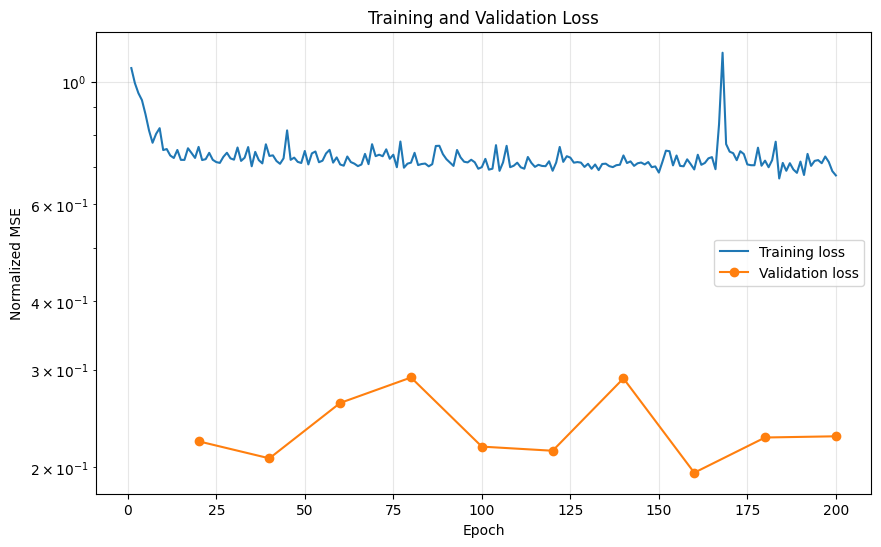

In [65]:
train_epochs = range(
    1,
    len(loss_history_train) + 1
)

plt.figure(figsize=(10, 6))

plt.semilogy(
    train_epochs,
    loss_history_train,
    label="Training loss",
)

plt.semilogy(
    val_epochs,
    loss_history_val,
    marker="o",
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")
plt.title("Training and Validation Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

## Results

In [ ]:
model.eval()

test_results = []


with torch.no_grad():

    for simulation_number, (
        X_test,
        Y_test,
        hierarchy_test
    ) in enumerate(train_loader, start=1):

        X_test = X_test.to(
            device,
            dtype=torch.float32,
            non_blocking=True
        )

        Y_test = Y_test.to(
            device,
            dtype=torch.float32,
            non_blocking=True
        )

        hierarchy_test = {
            name: tensor.to(
                device,
                dtype=(
                    torch.float32
                    if "dist" in name
                    else torch.long
                ),
                non_blocking=True
            )
            for name, tensor in hierarchy_test.items()
        }

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16,
            enabled=(device.type == "cuda")
        ):
            pred_test = model(
                X_test,
                hierarchy_test
            )

        # Convert normalized values back to actual temperatures
        pred_actual = (
            pred_test.float() * y_std.to(device)
        ) + y_mean.to(device)

        true_actual = (
            Y_test * y_std.to(device)
        ) + y_mean.to(device)

        # Convert to one-dimensional NumPy arrays
        pred_temp = (
            pred_actual
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        true_temp = (
            true_actual
            .detach()
            .cpu()
            .numpy()
            .reshape(-1)
        )

        error = pred_temp - true_temp

        mean_error = error.mean()
        error_std = error.std()
        mae = np.abs(error).mean()
        rmse = np.sqrt(np.mean(error * error))

        print(f"\nTest Simulation {simulation_number}")
        print(f"True temperature mean: {true_temp.mean():.4f}")
        print(f"Predicted temperature mean: {pred_temp.mean():.4f}")
        print(f"True temperature std: {true_temp.std():.4f}")
        print(f"Predicted temperature std: {pred_temp.std():.4f}")
        print(f"Mean error: {mean_error:.4f}")
        print(f"Error standard deviation: {error_std:.4f}")
        print(f"MAE: {mae:.4f}")
        print(f"RMSE: {rmse:.4f}")
        print(f"Minimum error: {error.min():.4f}")
        print(f"Maximum error: {error.max():.4f}")

        test_results.append(
            {
                "simulation": simulation_number,
                "true_temperature": true_temp,
                "predicted_temperature": pred_temp,
                "error": error,
                "mae": mae,
                "rmse": rmse,
                "mean_error": mean_error
            }
        )

        # Random subset for the scatter plot
        number_plot_points = min(
            100000,
            len(true_temp)
        )

        random_indices = np.random.default_rng(
            42
        ).choice(
            len(true_temp),
            size=number_plot_points,
            replace=False
        )

        minimum_temperature = min(
            true_temp.min(),
            pred_temp.min()
        )

        maximum_temperature = max(
            true_temp.max(),
            pred_temp.max()
        )

        figure, axes = plt.subplots(
            1,
            2,
            figsize=(14, 5)
        )

        # True versus predicted
        axes[0].scatter(
            true_temp[random_indices],
            pred_temp[random_indices],
            s=4,
            alpha=0.3
        )

        axes[0].plot(
            [
                minimum_temperature,
                maximum_temperature
            ],
            [
                minimum_temperature,
                maximum_temperature
            ],
            "r--",
            linewidth=2,
            label="Perfect prediction"
        )

        axes[0].set_xlabel("True Temperature")
        axes[0].set_ylabel("Predicted Temperature")

        axes[0].set_title(
            f"Predicted vs True Temperature\n"
            f"Test Simulation {simulation_number}"
        )

        axes[0].grid(
            True,
            alpha=0.3
        )

        axes[0].legend()

        # Error histogram
        axes[1].hist(
            error,
            bins=50,
            edgecolor="black",
            alpha=0.7
        )

        axes[1].axvline(
            0,
            color="red",
            linestyle="--",
            linewidth=2,
            label="Zero error"
        )

        axes[1].axvline(
            mean_error,
            color="orange",
            linestyle="--",
            linewidth=2,
            label=f"Mean error = {mean_error:.2f}"
        )

        axes[1].set_xlabel(
            "Predicted Temperature - True Temperature"
        )

        axes[1].set_ylabel("Count")

        axes[1].set_title(
            f"Prediction Error Distribution\n"
            f"Test Simulation {simulation_number}"
        )

        axes[1].grid(
            True,
            alpha=0.3
        )

        axes[1].legend()

        plt.tight_layout()
        plt.show()

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

## Debugger

In [34]:
# Get one fixed training simulation
X_one, Y_one, hierarchy_one = next(iter(train_loader))


# Move X and Y to GPU
X_one = X_one.to(
    device,
    dtype=torch.float32
)

Y_one = Y_one.to(
    device,
    dtype=torch.float32
)


# Move hierarchy to GPU with correct dtypes
hierarchy_one = {
    name: tensor.to(
        device,
        dtype=(
            torch.float32
            if "dist" in name
            else torch.long
        )
    )
    for name, tensor in hierarchy_one.items()
}


# Create a fresh model for this test
debug_model = ThermalPointNetPP().to(device)

debug_optimizer = torch.optim.Adam(
    debug_model.parameters(),
    lr=0.001
)

debug_criterion = torch.nn.MSELoss()


number_steps = 200
debug_loss_history = []


for step in range(number_steps):

    debug_model.train()

    debug_optimizer.zero_grad(
        set_to_none=True
    )

    # Use float32 first for reliable debugging
    prediction = debug_model(
        X_one,
        hierarchy_one
    )

    loss = debug_criterion(
        prediction,
        Y_one
    )

    if not torch.isfinite(loss):
        raise RuntimeError(
            f"Non-finite loss detected at step {step}: "
            f"{loss.item()}"
        )

    loss.backward()

    debug_optimizer.step()

    debug_loss_history.append(
        loss.item()
    )

    if step % 10 == 0:
        print(
            f"Step {step:3d}/{number_steps}, "
            f"Loss: {loss.item():.8f}, "
            f"RMSE: {math.sqrt(loss.item()):.8f}"
        )

Step   0/200, Loss: 0.51115710, RMSE: 0.71495251
Step  10/200, Loss: 0.44279981, RMSE: 0.66543205
Step  20/200, Loss: 0.24965873, RMSE: 0.49965862
Step  30/200, Loss: 0.18949926, RMSE: 0.43531513
Step  40/200, Loss: 0.18385009, RMSE: 0.42877744
Step  50/200, Loss: 0.17251825, RMSE: 0.41535317
Step  60/200, Loss: 0.13996254, RMSE: 0.37411568
Step  70/200, Loss: 0.12123267, RMSE: 0.34818483
Step  80/200, Loss: 0.10772707, RMSE: 0.32821802
Step  90/200, Loss: 0.10303799, RMSE: 0.32099531
Step 100/200, Loss: 0.09974976, RMSE: 0.31583185
Step 110/200, Loss: 0.09789113, RMSE: 0.31287558
Step 120/200, Loss: 0.09647841, RMSE: 0.31060974


KeyboardInterrupt: 

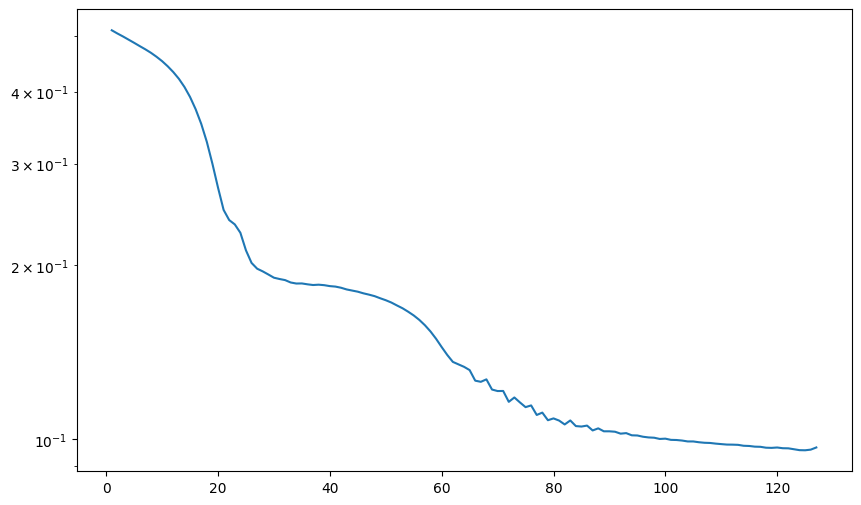

In [39]:
train_epochs = range(
    1,
    len(debug_loss_history) + 1
)

plt.figure(figsize=(10, 6))

plt.semilogy(
    train_epochs,
    debug_loss_history,
    label="Training loss",
)

In [35]:
debug_model.eval()

with torch.no_grad():
    final_prediction = debug_model(
        X_one,
        hierarchy_one
    )

constant_prediction = torch.full_like(
    Y_one,
    Y_one.mean()
)

baseline_loss = debug_criterion(
    constant_prediction,
    Y_one
)

final_loss = debug_criterion(
    final_prediction,
    Y_one
)

print(
    "Constant-mean baseline loss:",
    baseline_loss.item()
)

print(
    "Final model loss:",
    final_loss.item()
)

print(
    "Target standard deviation:",
    Y_one.std().item()
)

print(
    "Prediction standard deviation:",
    final_prediction.std().item()
)

Constant-mean baseline loss: 0.5055606365203857
Final model loss: 0.10114561766386032
Target standard deviation: 0.7110282778739929
Prediction standard deviation: 0.6121087670326233


In [104]:
def evaluate_loader(model, loader, criterion, device):

    model.eval()

    loss_sum = 0.0

    with torch.no_grad():

        for X, Y, hierarchy in loader:

            X = X.to(
                device,
                dtype=torch.float32,
                non_blocking=True
            )

            Y = Y.to(
                device,
                dtype=torch.float32,
                non_blocking=True
            )

            hierarchy = {
                name: tensor.to(
                    device,
                    dtype=(
                        torch.float32
                        if "dist" in name
                        else torch.long
                    ),
                    non_blocking=True
                )
                for name, tensor in hierarchy.items()
            }

            prediction = model(
                X,
                hierarchy
            )

            loss = criterion(
                prediction,
                Y
            )

            loss_sum += loss.item()

    return loss_sum / len(loader)

In [105]:
train_eval_loss = evaluate_loader(
    model,
    train_loader,
    criterion,
    device
)

val_eval_loss = evaluate_loader(
    model,
    val_loader,
    criterion,
    device
)

print("Training loss during updates:", train_loss)
print("Training loss after epoch:", train_eval_loss)
print("Validation loss after epoch:", val_eval_loss)

Training loss during updates: 0.8967747241258621
Training loss after epoch: 0.7821533560752869
Validation loss after epoch: 0.2605302333831787


In [90]:
def print_baseline_losses(
    simulations,
    split_name
):
    print(f"\n{split_name}")

    for index, (_, Y, _) in enumerate(
        simulations,
        start=1
    ):
        simulation_mean_prediction = torch.full_like(
            Y,
            Y.mean()
        )

        global_mean_prediction = torch.zeros_like(
            Y
        )

        simulation_mean_mse = torch.mean(
            (
                simulation_mean_prediction - Y
            ) ** 2
        )

        global_mean_mse = torch.mean(
            (
                global_mean_prediction - Y
            ) ** 2
        )

        print(
            f"Simulation {index}: "
            f"mean={Y.mean().item():.6f}, "
            f"std={Y.std().item():.6f}, "
            f"simulation-mean baseline={simulation_mean_mse.item():.6f}, "
            f"global-mean baseline={global_mean_mse.item():.6f}"
        )

In [91]:
print_baseline_losses(
    train_sims,
    "Training simulations"
)

print_baseline_losses(
    val_sims,
    "Validation simulation"
)


Training simulations
Simulation 1: mean=1.148767, std=0.704057, simulation-mean baseline=0.495695, global-mean baseline=1.815360
Simulation 2: mean=1.107551, std=0.643087, simulation-mean baseline=0.413561, global-mean baseline=1.640231
Simulation 3: mean=0.357509, std=0.834821, simulation-mean baseline=0.696926, global-mean baseline=0.824738
Simulation 4: mean=0.301606, std=0.797451, simulation-mean baseline=0.635927, global-mean baseline=0.726894
Simulation 5: mean=0.246770, std=0.684423, simulation-mean baseline=0.468434, global-mean baseline=0.529329
Simulation 6: mean=0.267290, std=0.696698, simulation-mean baseline=0.485387, global-mean baseline=0.556831
Simulation 7: mean=-0.829706, std=0.566373, simulation-mean baseline=0.320778, global-mean baseline=1.009190
Simulation 8: mean=-0.836822, std=0.557075, simulation-mean baseline=0.310332, global-mean baseline=1.010603
Simulation 9: mean=-0.851811, std=0.540985, simulation-mean baseline=0.292665, global-mean baseline=1.018247
Sim

In [92]:
def evaluate_per_simulation(
    model,
    loader,
    criterion,
    device,
    split_name
):
    model.eval()

    print(f"\n{split_name}")

    model_losses = []
    relative_losses = []

    with torch.no_grad():

        for index, (X, Y, hierarchy) in enumerate(
            loader,
            start=1
        ):
            X = X.to(
                device,
                dtype=torch.float32
            )

            Y = Y.to(
                device,
                dtype=torch.float32
            )

            hierarchy = {
                name: tensor.to(
                    device,
                    dtype=(
                        torch.float32
                        if "dist" in name
                        else torch.long
                    )
                )
                for name, tensor in hierarchy.items()
            }

            prediction = model(
                X,
                hierarchy
            )

            model_mse = criterion(
                prediction,
                Y
            )

            global_baseline_mse = torch.mean(
                Y ** 2
            )

            relative_loss = (
                model_mse / global_baseline_mse
            )

            model_losses.append(
                model_mse.item()
            )

            relative_losses.append(
                relative_loss.item()
            )

            print(
                f"Simulation {index}: "
                f"Model MSE={model_mse.item():.6f}, "
                f"Baseline={global_baseline_mse.item():.6f}, "
                f"Relative Loss={relative_loss.item():.4f}, "
                f"Target Mean={Y.mean().item():.4f}, "
                f"Prediction Mean={prediction.mean().item():.4f}, "
                f"Target Std={Y.std().item():.4f}, "
                f"Prediction Std={prediction.std().item():.4f}"
            )

    print(
        f"\nAverage {split_name} MSE:",
        sum(model_losses) / len(model_losses)
    )

    print(
        f"Average {split_name} relative loss:",
        sum(relative_losses) / len(relative_losses)
    )

In [94]:
evaluate_per_simulation(
    model,
    train_loader,
    criterion,
    device,
    "Training"
)

evaluate_per_simulation(
    model,
    val_loader,
    criterion,
    device,
    "Validation"
)


Training
Simulation 1: Model MSE=0.170333, Baseline=0.529329, Relative Loss=0.3218, Target Mean=0.2468, Prediction Mean=0.0307, Target Std=0.6844, Prediction Std=0.5766
Simulation 2: Model MSE=0.863470, Baseline=1.018777, Relative Loss=0.8476, Target Mean=-0.8197, Prediction Mean=0.0535, Target Std=0.5890, Prediction Std=0.5851
Simulation 3: Model MSE=0.912525, Baseline=1.018247, Relative Loss=0.8962, Target Mean=-0.8518, Prediction Mean=0.0543, Target Std=0.5410, Prediction Std=0.5887
Simulation 4: Model MSE=0.289690, Baseline=0.824738, Relative Loss=0.3513, Target Mean=0.3575, Prediction Mean=0.0316, Target Std=0.8348, Prediction Std=0.5874
Simulation 5: Model MSE=0.893649, Baseline=1.010603, Relative Loss=0.8843, Target Mean=-0.8368, Prediction Mean=0.0558, Target Std=0.5571, Prediction Std=0.5910
Simulation 6: Model MSE=0.883922, Baseline=1.009190, Relative Loss=0.8759, Target Mean=-0.8297, Prediction Mean=0.0561, Target Std=0.5664, Prediction Std=0.5823
Simulation 7: Model MSE=0.